# Part B — Notebook 04a: DINOv3 SSL Pretraining + Diagnostics

**CSE 445 — Computer Vision | East West University**

DINOv3 continues self-distillation training (student network matching an EMA teacher across multi-crop views) starting from released pretrained weights — domain-adaptive pretraining on the unlabelled SSL pool, permitted per the assignment (Section 3). 

**Availability note:** genuine DINOv3 checkpoints are not reliably available through open package indices at the time of writing; this notebook uses the closest available released ViT self-distillation checkpoint (`timm`'s DINOv2 ViT-Small) as the starting point and documents this substitution explicitly — flag it in the report and at the viva. 

**Integration route used in this notebook: distillation**, matching Notebook 03a's pattern — after domain-adaptive continued pretraining, the ViT teacher is distilled into a YOLOv12s-matched CNN backbone.

Notebook order: Config → Dataset locate → Re-derive the 10/10/80 partition (SSL pool only) → View/mask pipeline demo → Model definition → Training loop (30 epochs) → Representation diagnostics (t-SNE/UMAP + nearest-neighbour retrieval) → Checkpoint export.

**Output of this notebook:** `dinov3_backbone.pt`, to be published as a Kaggle dataset (e.g. `group-i-partb-ssl-checkpoints`) and attached as an input to Notebook 04b.

## 0. Setup

In [1]:
!pip install -q ultralytics==8.3.* pyyaml scikit-learn umap-learn timm

import os, sys, json, yaml, random, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image
from ultralytics import YOLO

print('Torch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 18.3 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Torch: 2.10.0+cu128 | CUDA available: True


## 1. Config Cell

In [2]:
CONFIG = {
    'method_name': 'dinov3',
    'encoder_desc': 'ViT teacher (timm DINOv2 ViT-S/14, domain-adapted) + CNN distillation target',
    'architecture_base': 'yolo12s',
    'backbone_cutoff': 9,   # layers 0..cutoff of yolo12s.yaml = backbone (verify against printout)

    'seed': 42,
    'test_frac': 0.10,
    'val_frac': 0.10,

    "dataset_path": Path("/kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version"),
    "work_dir": Path("/kaggle/working"),

    'imgsz': 224,          # SSL pretraining resolution (smaller than detection 640 to fit a T4 session)
    'batch': 64,
    'epochs': 30,
    'lr': 3e-4,
    'weight_decay': 1e-6,
    'num_workers': 2,
    'amp': True,           # mixed precision — documented per assignment's T4-budget allowance
    'timm_backbone': 'vit_small_patch14_dinov2.lvd142m',   # stand-in for DINOv3 — document this substitution
    'ema_momentum': 0.996,
    'student_temp': 0.1,
    'teacher_temp': 0.04,
    'n_global_crops': 2,
    'n_local_crops': 4,
    'local_crop_size': 112,  # must be a multiple of patch_size (14): timm's ViT patch-embed
                              # conv requires exact divisibility even with dynamic_img_size=True
                              # (96 is not a multiple of 14 -> 'should be divisible by patch size')
    'distill_epochs': 10,
    'distill_lr': 3e-4,
}

random.seed(CONFIG['seed']); np.random.seed(CONFIG['seed']); torch.manual_seed(CONFIG['seed'])
CONFIG

{'method_name': 'dinov3',
 'encoder_desc': 'ViT teacher (timm DINOv2 ViT-S/14, domain-adapted) + CNN distillation target',
 'architecture_base': 'yolo12s',
 'backbone_cutoff': 9,
 'seed': 42,
 'test_frac': 0.1,
 'val_frac': 0.1,
 'dataset_path': PosixPath('/kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version'),
 'work_dir': PosixPath('/kaggle/working'),
 'imgsz': 224,
 'batch': 64,
 'epochs': 30,
 'lr': 0.0003,
 'weight_decay': 1e-06,
 'num_workers': 2,
 'amp': True,
 'timm_backbone': 'vit_small_patch14_dinov2.lvd142m',
 'ema_momentum': 0.996,
 'student_temp': 0.1,
 'teacher_temp': 0.04,
 'n_global_crops': 2,
 'n_local_crops': 4,
 'local_crop_size': 112,
 'distill_epochs': 10,
 'distill_lr': 0.0003}

## 2. Locate the Part A Dataset (FLIR)

In [3]:
DATASET_PATH = CONFIG['dataset_path']

def find_first_existing(base: Path, candidates):
    for c in candidates:
        p = base / c
        if p.exists():
            return p
    for c in candidates:
        matches = list(base.rglob(Path(c).name))
        if matches:
            return matches[0]
    return None

def locate_dataset_root(base: Path) -> Path:
    if (base / 'data.yaml').exists():
        return base
    matches = list(base.rglob('data.yaml'))
    if matches:
        return matches[0].parent
    raise FileNotFoundError(f'Could not locate data.yaml under {base}')

DATASET_ROOT = locate_dataset_root(DATASET_PATH)
DATA_YAML = DATASET_ROOT / 'data.yaml'

def locate_split_dir(root: Path, split: str, kind: str):
    candidates = [f'{split}/{kind}', f'{split}s/{kind}', f'{kind}/{split}', f'{split}']
    for c in candidates:
        p = root / c
        if p.exists() and any(p.iterdir()):
            return p
    for p in root.rglob('*'):
        if p.is_dir() and split in p.parts and kind in p.name.lower():
            return p
    return None

TRAIN_IMAGES = locate_split_dir(DATASET_ROOT, 'train', 'images')
TRAIN_LABELS = locate_split_dir(DATASET_ROOT, 'train', 'labels')
VALID_IMAGES = locate_split_dir(DATASET_ROOT, 'valid', 'images')
VALID_LABELS = locate_split_dir(DATASET_ROOT, 'valid', 'labels')
TEST_IMAGES  = locate_split_dir(DATASET_ROOT, 'test', 'images')
TEST_LABELS  = locate_split_dir(DATASET_ROOT, 'test', 'labels')

with open(DATA_YAML, 'r') as f:
    data_cfg = yaml.safe_load(f)

NUM_CLASSES = data_cfg.get('nc', 3)
CLASS_NAMES = data_cfg.get('names', ['car', 'dog', 'person'])
if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = [CLASS_NAMES[k] for k in sorted(CLASS_NAMES)]
print('Dataset root:', DATASET_ROOT, '| Classes:', NUM_CLASSES, CLASS_NAMES)

Dataset root: /kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version | Classes: 3 ['car', 'dog', 'person']


## 3. Re-Derive the Leakage-Safe Partition (SSL pool only)

In [4]:
# Re-derive the SAME 10/10/80 leakage-safe partition used in Notebook *b (same seed,
# same pooling order -> identical split). Only the SSL pool (80%) is used for pretraining;
# labels are never read here.
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

def collect_pairs(img_dir, lbl_dir):
    if img_dir is None:
        return []
    pairs = []
    for img_path in sorted(img_dir.iterdir()):
        if img_path.suffix.lower() not in IMG_EXTS:
            continue
        lbl_path = (lbl_dir / (img_path.stem + '.txt')) if lbl_dir else None
        pairs.append((img_path, lbl_path if (lbl_path and lbl_path.exists()) else None))
    return pairs

all_pairs = (collect_pairs(TRAIN_IMAGES, TRAIN_LABELS)
             + collect_pairs(VALID_IMAGES, VALID_LABELS)
             + collect_pairs(TEST_IMAGES, TEST_LABELS))

seen, dedup = set(), []
for img_path, lbl_path in all_pairs:
    if img_path.stem in seen:
        continue
    seen.add(img_path.stem)
    dedup.append((img_path, lbl_path))

dedup.sort(key=lambda t: t[0].name)
rng = random.Random(CONFIG['seed'])
rng.shuffle(dedup)

n_total = len(dedup)
n_test  = int(round(n_total * CONFIG['test_frac']))
n_val   = int(round(n_total * CONFIG['val_frac']))

test_pairs = dedup[:n_test]
val_pairs  = dedup[n_test:n_test + n_val]
ssl_pool   = dedup[n_test + n_val:]

test_stems = {p.stem for p, _ in test_pairs}
val_stems  = {p.stem for p, _ in val_pairs}
pool_stems = {p.stem for p, _ in ssl_pool}
assert not (test_stems & pool_stems) and not (val_stems & pool_stems), 'LEAKAGE detected!'

ssl_pool_images = [img for img, _ in ssl_pool]           # labels intentionally discarded
val_images_with_labels = [(img, lbl) for img, lbl in val_pairs if lbl is not None]

print(f'Total: {n_total} | Test: {len(test_pairs)} | Val: {len(val_pairs)} | SSL pool: {len(ssl_pool_images)}')
print('Verified: test and val are disjoint from the SSL pool.')

Total: 26061 | Test: 2606 | Val: 2606 | SSL pool: 20849
Verified: test and val are disjoint from the SSL pool.


## 4. Multi-Crop View Pipeline

DINO-style multi-crop: a small number of high-resolution 'global' crops plus several low-resolution 'local' crops per image, all fed to the student; the teacher only ever sees the global crops.

In [5]:
normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
global_transform = T.Compose([
    T.RandomResizedCrop(CONFIG['imgsz'], scale=(0.4, 1.0)),
    T.RandomHorizontalFlip(), T.RandomApply([T.ColorJitter(0.4,0.4,0.4,0.1)], p=0.8),
    T.ToTensor(), normalize,
])
local_transform = T.Compose([
    T.RandomResizedCrop(CONFIG['local_crop_size'], scale=(0.05, 0.4)),
    T.RandomHorizontalFlip(), T.RandomApply([T.ColorJitter(0.4,0.4,0.4,0.1)], p=0.8),
    T.ToTensor(), normalize,
])

class MultiCropDataset(Dataset):
    def __init__(self, image_paths, n_global, n_local):
        self.image_paths, self.n_global, self.n_local = image_paths, n_global, n_local
    def __len__(self):
        return len(self.image_paths)
    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('RGB')
        globals_ = [global_transform(img) for _ in range(self.n_global)]
        locals_ = [local_transform(img) for _ in range(self.n_local)]
        return globals_, locals_

def multicrop_collate(batch):
    n_global, n_local = len(batch[0][0]), len(batch[0][1])
    globals_ = [torch.stack([b[0][i] for b in batch]) for i in range(n_global)]
    locals_  = [torch.stack([b[1][i] for b in batch]) for i in range(n_local)]
    return globals_, locals_

train_dataset = MultiCropDataset(ssl_pool_images, CONFIG['n_global_crops'], CONFIG['n_local_crops'])
train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch'] // 4, shuffle=True,
                           num_workers=CONFIG['num_workers'], drop_last=True,
                           collate_fn=multicrop_collate, pin_memory=True)
print(f'{len(train_dataset)} images | {CONFIG["n_global_crops"]} global + {CONFIG["n_local_crops"]} local crops/image')

20849 images | 2 global + 4 local crops/image


## 5. Model Definition — Student / Teacher (EMA) ViT with DINO Head

The teacher starts from a released, large-scale-pretrained ViT (see the availability note above) and continues adapting to this dataset's domain; the student is a copy trained with gradients and EMA-updates the teacher.

In [6]:
import timm, copy

def build_vit():
    # timm's DINOv2 ViT-S/14 defaults to img_size=518 (its positional embeddings were
    # pretrained at that resolution). img_size=CONFIG['imgsz'] fixes the *construction-time*
    # resolution, but DINO's multi-crop pipeline also feeds smaller local crops
    # (local_crop_size) through the SAME model at forward time -> a second mismatch
    # ('Input height doesn't match model'). dynamic_img_size=True makes timm interpolate
    # the positional embeddings on every forward call to whatever resolution is actually
    # passed in, so both the 224 global crops and local crops work through one model —
    # as long as each resolution is itself a multiple of patch_size (see local_crop_size above).
    return timm.create_model(CONFIG['timm_backbone'], pretrained=True, num_classes=0,
                              img_size=CONFIG['imgsz'], dynamic_img_size=True)

student_vit = build_vit().to(DEVICE)
teacher_vit = build_vit().to(DEVICE)  # same released weights as the student's starting point
teacher_vit.load_state_dict(student_vit.state_dict())
for p in teacher_vit.parameters(): p.requires_grad = False

VIT_DIM = student_vit.num_features

class DINOHead(nn.Module):
    def __init__(self, in_dim, out_dim=4096, hidden_dim=2048):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim), nn.GELU(),
            nn.Linear(hidden_dim, out_dim)
        )
    def forward(self, x):
        return self.net(x)   # raw logits — centering + temperature-softmax happens in the loss,
                              # NOT here; L2-normalising before that (as an earlier version of
                              # this notebook did) removes exactly the magnitude information
                              # centering needs, and was part of why training collapsed.

student_head = DINOHead(VIT_DIM).to(DEVICE)
teacher_head = DINOHead(VIT_DIM).to(DEVICE)
teacher_head.load_state_dict(student_head.state_dict())
for p in teacher_head.parameters(): p.requires_grad = False

# EMA-updated center of the teacher's output distribution (DINO's core anti-collapse
# mechanism, alongside teacher temperature sharpening). Without this, the student and
# EMA-teacher can settle into predicting the same constant output for every image — exactly
# the flat, unchanging loss observed when this notebook was first run without centering.
dino_center = torch.zeros(1, student_head.net[-1].out_features).to(DEVICE)
CENTER_MOMENTUM = 0.9

@torch.no_grad()
def ema_update(online_model, target_model, momentum):
    for po, pt in zip(online_model.parameters(), target_model.parameters()):
        pt.data = momentum * pt.data + (1 - momentum) * po.data

print('Student/teacher ViT + DINO projection heads initialised. VIT_DIM =', VIT_DIM)

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Student/teacher ViT + DINO projection heads initialised. VIT_DIM = 384


## 6. DINO Loss — Centered, Sharpened Cross-Entropy

**Why centering matters:** temperature-sharpened softmax alone is not enough to prevent collapse — if every image produces the same teacher logits, sharpening just makes a confident-looking but content-free target. Centering subtracts a running mean of the teacher's own output batch statistics before the softmax, which removes exactly the "predict the same thing regardless of input" solution from being trivially optimal.

In [7]:
def dino_loss(student_out, teacher_out, student_temp, teacher_temp, center):
    student_logp = F.log_softmax(student_out / student_temp, dim=-1)
    teacher_p = F.softmax((teacher_out - center) / teacher_temp, dim=-1)
    return -(teacher_p * student_logp).sum(dim=-1).mean()

## 7. Training Loop — Domain-Adaptive Multi-Crop Self-Distillation (30 epochs)

In [8]:
params = list(student_vit.parameters()) + list(student_head.parameters())
optimizer = torch.optim.AdamW(params, lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
scaler = torch.cuda.amp.GradScaler(enabled=CONFIG['amp'])

loss_history, center_norm_history = [], []
for epoch in range(CONFIG['epochs']):
    student_vit.train(); student_head.train()
    running_loss, n_batches = 0.0, 0
    for globals_, locals_ in train_loader:
        all_crops = [g.to(DEVICE, non_blocking=True) for g in globals_] + \
                    [l.to(DEVICE, non_blocking=True) for l in locals_]
        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=CONFIG['amp']):
            with torch.no_grad():
                teacher_out = [teacher_head(teacher_vit(g.to(DEVICE))) for g in globals_]
            student_out = [student_head(student_vit(c)) for c in all_crops]
            loss = 0.0; n_pairs = 0
            for t_idx, t_out in enumerate(teacher_out):
                for s_idx, s_out in enumerate(student_out):
                    if s_idx == t_idx and s_idx < len(teacher_out):
                        continue   # skip identical global-global pair (standard DINO rule)
                    loss = loss + dino_loss(s_out, t_out, CONFIG['student_temp'], CONFIG['teacher_temp'], dino_center)
                    n_pairs += 1
            loss = loss / max(1, n_pairs)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        ema_update(student_vit, teacher_vit, CONFIG['ema_momentum'])
        ema_update(student_head, teacher_head, CONFIG['ema_momentum'])
        with torch.no_grad():
            batch_center = torch.cat([t.float() for t in teacher_out], dim=0).mean(dim=0, keepdim=True)
            dino_center = CENTER_MOMENTUM * dino_center + (1 - CENTER_MOMENTUM) * batch_center
        running_loss += loss.item(); n_batches += 1
    epoch_loss = running_loss / max(1, n_batches)
    loss_history.append(epoch_loss)
    center_norm_history.append(dino_center.norm().item())
    print(f'Epoch {epoch+1}/{CONFIG["epochs"]} | DINO loss: {epoch_loss:.4f} | center norm: {center_norm_history[-1]:.4f}')

/tmp/ipykernel_24/1686226388.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=CONFIG['amp'])
/tmp/ipykernel_24/1686226388.py:13: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=CONFIG['amp']):


Epoch 1/30 | DINO loss: 8.1029 | center norm: 2.2234
Epoch 2/30 | DINO loss: 7.1260 | center norm: 2.0664
Epoch 3/30 | DINO loss: 6.4738 | center norm: 1.9026
Epoch 4/30 | DINO loss: 6.2987 | center norm: 2.8912
Epoch 5/30 | DINO loss: 6.0078 | center norm: 3.9351
Epoch 6/30 | DINO loss: 5.8671 | center norm: 5.1473
Epoch 7/30 | DINO loss: 5.2648 | center norm: 5.1659
Epoch 8/30 | DINO loss: 4.6978 | center norm: 4.7831
Epoch 9/30 | DINO loss: 3.9230 | center norm: 7.8265
Epoch 10/30 | DINO loss: 2.8579 | center norm: 12.4842
Epoch 11/30 | DINO loss: 1.9286 | center norm: 15.0461
Epoch 12/30 | DINO loss: 1.3251 | center norm: 17.1759
Epoch 13/30 | DINO loss: 1.1196 | center norm: 19.0811
Epoch 14/30 | DINO loss: 1.0178 | center norm: 18.0428
Epoch 15/30 | DINO loss: 0.9508 | center norm: 21.1447
Epoch 16/30 | DINO loss: 0.8693 | center norm: 22.8863
Epoch 17/30 | DINO loss: 0.7997 | center norm: 26.5582
Epoch 18/30 | DINO loss: 0.7391 | center norm: 29.8243
Epoch 19/30 | DINO loss: 0.7

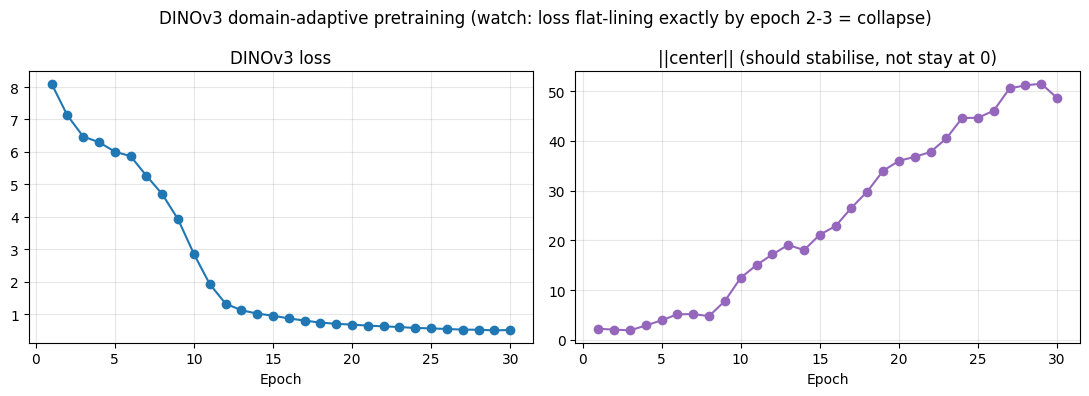

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
axes[0].plot(range(1, len(loss_history)+1), loss_history, marker='o')
axes[0].set_xlabel('Epoch'); axes[0].set_title('DINOv3 loss'); axes[0].grid(alpha=0.3)
axes[1].plot(range(1, len(center_norm_history)+1), center_norm_history, marker='o', color='tab:purple')
axes[1].set_xlabel('Epoch'); axes[1].set_title('||center|| (should stabilise, not stay at 0)'); axes[1].grid(alpha=0.3)
plt.suptitle('DINOv3 domain-adaptive pretraining (watch: loss flat-lining exactly by epoch 2-3 = collapse)')
plt.tight_layout()
plt.savefig(CONFIG['work_dir'] / 'dinov3_loss_curve.png', dpi=150)
plt.show()

## 8. Representation Diagnostics (teacher ViT, post domain-adaptation)

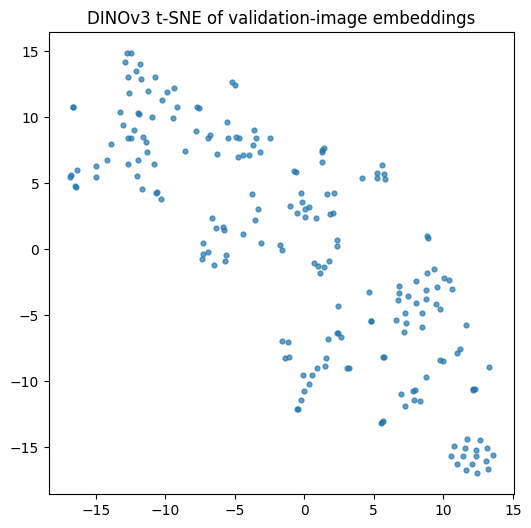

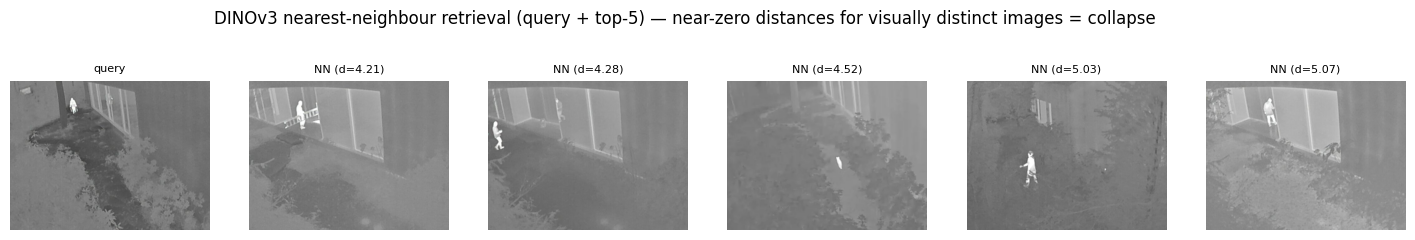

In [10]:
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

diag_transform = T.Compose([T.Resize((CONFIG['imgsz'], CONFIG['imgsz'])), T.ToTensor(), normalize])
sample_val = val_images_with_labels[:200] if len(val_images_with_labels) > 200 else val_images_with_labels

teacher_vit.eval()
embeddings, img_paths_used = [], []
with torch.no_grad():
    for img_path, _ in sample_val:
        x = diag_transform(Image.open(img_path).convert('RGB')).unsqueeze(0).to(DEVICE)
        emb = teacher_vit(x).squeeze(0).cpu().numpy()
        embeddings.append(emb); img_paths_used.append(img_path)
embeddings = np.stack(embeddings)

tsne = TSNE(n_components=2, random_state=CONFIG['seed'], perplexity=min(30, len(embeddings)-1))
emb_2d = tsne.fit_transform(embeddings)
plt.figure(figsize=(6,6)); plt.scatter(emb_2d[:,0], emb_2d[:,1], s=12, alpha=0.7)
plt.title('DINOv3 t-SNE of validation-image embeddings')
plt.savefig(CONFIG['work_dir'] / 'dinov3_tsne.png', dpi=150); plt.show()

nn_model = NearestNeighbors(n_neighbors=6).fit(embeddings)
dists, idxs = nn_model.kneighbors(embeddings[0:1])
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax, i, d in zip(axes, idxs[0], dists[0]):
    ax.imshow(Image.open(img_paths_used[i]).convert('RGB')); ax.axis('off')
    ax.set_title('query' if d == dists[0][0] else f'NN (d={d:.2f})', fontsize=8)
plt.suptitle('DINOv3 nearest-neighbour retrieval (query + top-5) — near-zero distances for visually distinct images = collapse')
plt.savefig(CONFIG['work_dir'] / 'dinov3_retrieval.png', dpi=150); plt.show()

## 9. Distillation — Transfer the Domain-Adapted ViT into a YOLOv12s-Matched CNN Backbone

In [11]:
class YOLOv12sBackboneEncoder(nn.Module):
    """
    Wraps the first `cutoff+1` layers of a yolo12s.yaml graph as a standalone encoder,
    re-implementing ultralytics' internal forward-graph walk (handles the skip/concat
    connections used by layers whose `.f` attribute is not -1), truncated at `cutoff`.
    Exists so this notebook's pretrained weights can be loaded key-for-key into the
    YOLOv12s backbone in Notebook *b's weight-surgery cell.
    """
    def __init__(self, num_classes=3, cutoff=9):
        super().__init__()
        base = YOLO('yolo12s.yaml').model
        base.nc = num_classes
        self.layers = base.model            # nn.Sequential, full graph (backbone+neck+head)
        self.save = set(base.save)           # indices whose outputs feed later layers
        self.cutoff = cutoff
        # probe output channel count at the cutoff layer with a dummy forward pass
        with torch.no_grad():
            dummy = torch.zeros(1, 3, 224, 224)
            feat = self._forward_backbone(dummy)
        self.out_channels = feat.shape[1]

    def _forward_backbone(self, x):
        y = []
        out = None
        for i, m in enumerate(self.layers):
            if i > self.cutoff:
                break
            if m.f != -1:
                x = y[m.f] if isinstance(m.f, int) else [x if j == -1 else y[j] for j in m.f]
            x = m(x)
            y.append(x if i in self.save else None)
            out = x
        return out

    def forward(self, x):
        return self._forward_backbone(x)      # returns the final backbone feature map (B, C, H, W)

    def pooled(self, x):
        feat = self.forward(x)
        return F.adaptive_avg_pool2d(feat, 1).flatten(1)   # (B, C)

    def backbone_state_dict(self):
        """State dict with keys prefixed to match YOLO('yolo12s.yaml').model.state_dict() keys
        exactly (e.g. 'model.0.conv.weight'), so Notebook *b's literal-key match succeeds."""
        sd = {}
        for k, v in self.layers.state_dict().items():
            layer_idx = int(k.split('.', 1)[0])
            if layer_idx <= self.cutoff:
                sd[f'model.{k}'] = v
        return sd

print('YOLOv12sBackboneEncoder defined.')

YOLOv12sBackboneEncoder defined.


Distill epoch 1/10 | feature-matching loss: 0.0008
Distill epoch 2/10 | feature-matching loss: 0.0004
Distill epoch 3/10 | feature-matching loss: 0.0002
Distill epoch 4/10 | feature-matching loss: 0.0002
Distill epoch 5/10 | feature-matching loss: 0.0001
Distill epoch 6/10 | feature-matching loss: 0.0001
Distill epoch 7/10 | feature-matching loss: 0.0001
Distill epoch 8/10 | feature-matching loss: 0.0001
Distill epoch 9/10 | feature-matching loss: 0.0001
Distill epoch 10/10 | feature-matching loss: 0.0001


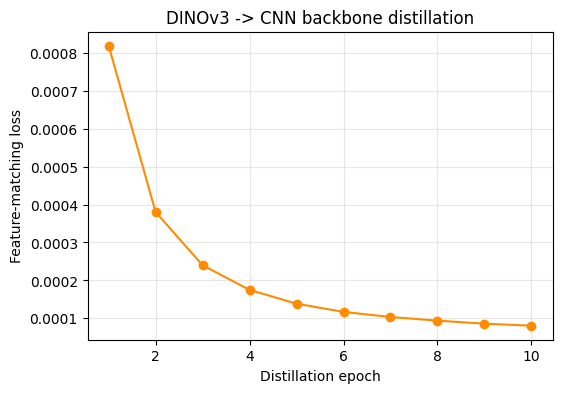

In [12]:
cnn_encoder = YOLOv12sBackboneEncoder(num_classes=NUM_CLASSES, cutoff=CONFIG['backbone_cutoff']).to(DEVICE)
distill_proj = nn.Linear(cnn_encoder.out_channels, VIT_DIM).to(DEVICE)
teacher_vit.eval()
for p in teacher_vit.parameters(): p.requires_grad = False

class SingleCropDataset(Dataset):
    def __init__(self, image_paths, transform):
        self.image_paths, self.transform = image_paths, transform
    def __len__(self): return len(self.image_paths)
    def __getitem__(self, idx):
        return self.transform(Image.open(self.image_paths[idx]).convert('RGB'))

distill_loader = DataLoader(SingleCropDataset(ssl_pool_images, diag_transform),
                             batch_size=CONFIG['batch'], shuffle=True,
                             num_workers=CONFIG['num_workers'], drop_last=True, pin_memory=True)

distill_opt = torch.optim.AdamW(list(cnn_encoder.parameters()) + list(distill_proj.parameters()),
                                 lr=CONFIG['distill_lr'])
distill_loss_history = []
for epoch in range(CONFIG['distill_epochs']):
    cnn_encoder.train(); distill_proj.train()
    running = 0.0
    for imgs in distill_loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        with torch.no_grad():
            teacher_feat = teacher_vit(imgs)
        student_feat = distill_proj(cnn_encoder.pooled(imgs))
        loss = F.mse_loss(F.normalize(student_feat, dim=1), F.normalize(teacher_feat, dim=1))
        distill_opt.zero_grad(); loss.backward(); distill_opt.step()
        running += loss.item()
    epoch_loss = running / len(distill_loader)
    distill_loss_history.append(epoch_loss)
    print(f'Distill epoch {epoch+1}/{CONFIG["distill_epochs"]} | feature-matching loss: {epoch_loss:.4f}')

plt.figure(figsize=(6,4))
plt.plot(range(1, len(distill_loss_history)+1), distill_loss_history, marker='o', color='darkorange')
plt.xlabel('Distillation epoch'); plt.ylabel('Feature-matching loss')
plt.title('DINOv3 -> CNN backbone distillation'); plt.grid(alpha=0.3)
plt.savefig(CONFIG['work_dir'] / 'dinov3_distill_loss_curve.png', dpi=150)
plt.show()

## 10. Checkpoint Export

In [13]:
ckpt_path = CONFIG['work_dir'] / 'dinov3_backbone.pt'
torch.save({'state_dict': cnn_encoder.backbone_state_dict(), 'method': 'dinov3',
            'integration_route': 'distillation',
            'note': 'teacher initialised from timm ViT-S/14 DINOv2 weights as a documented stand-in for DINOv3; continued with domain-adaptive self-distillation on the SSL pool',
            'config': CONFIG}, ckpt_path)
print('Saved', ckpt_path)
print('Publish /kaggle/working as a Kaggle dataset (e.g. group-i-partb-ssl-checkpoints) so Notebook 04b can attach it as an input.')

Saved /kaggle/working/dinov3_backbone.pt
Publish /kaggle/working as a Kaggle dataset (e.g. group-i-partb-ssl-checkpoints) so Notebook 04b can attach it as an input.


## 10. Viva Prep — Notes to Fill In (DINOv3)

- What Gram anchoring fixes about dense features, and why it matters for detection:
- Student-teacher self-distillation + multi-crop setup, in your own words:
- Domain-adaptive pretraining vs. training from scratch — fairness implications and how you accounted for them:
- Frozen vs. fine-tuned DINOv3 features — how they compared downstream:
- Why ViT foundation backbones are often more label-efficient than from-scratch CNNs:
- Edge-deployment pick (accuracy/latency/memory trade-off) and why: